## 1. Data loading

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

BASE_URL = "https://michael-weylandt.com/STA9890/competition_data/"

train_df = pd.read_csv(BASE_URL + "scores_training.csv")
test_df = pd.read_csv(BASE_URL + "scores_test.csv")
schools = pd.read_csv(BASE_URL + "school_covariates.csv")
district = pd.read_csv(BASE_URL + "district_covariates.csv")

print(f"Training rows: {len(train_df):>7,}")
print(f"Test rows:     {len(test_df):>7,}")
print(f"Schools:       {len(schools):>7,}")
print(f"Districts:     {len(district):>7,}")

Training rows: 144,921
Test rows:      48,307
Schools:         4,754
Districts:         674


## 2. Joining the tables


In [ ]:
# Left-join schools onto training data
df = train_df.merge(schools, on="SCHOOL", how="left")

# The left join should not change the row count
assert len(df) == len(train_df), "Left join with schools changed row count"

# Left-join district graduation data on DISTRICT
df = df.merge(district, on="DISTRICT", how="left")
assert len(df) == len(train_df), "Left join with district changed row count"

print(f"Combined dataframe: {df.shape[0]:,} rows x {df.shape[1]} columns")

Combined dataframe: 144,921 rows x 62 columns


## 3. Handling missing data

In [ ]:
na_summary = pd.DataFrame({
    "n_missing": df.isna().sum(),
    "percent_missing": df.isna().mean() * 100,
}).sort_values("percent_missing", ascending=False)

na_summary.head(15)

,n_missing,percent_missing
TEACHER_TURNOVER_RATE,134136,92.558014
KINDERGARTEN_AVERAGE_CLASS_SIZE,103467,71.395450
GRADE_1_AVERAGE_CLASS_SIZE,102899,71.003512
GRADE_2_AVERAGE_CLASS_SIZE,102779,70.920709
HISTORY_GOVERNMENT_AND_GEOGRAPHY_AVERAGE_CLASS_SIZE,89314,61.629439
PERCENT_DROPOUT,16061,11.082590
PERCENT_DIPLOMA,16061,11.082590
PERCENT_STILL_ENROLLED,16061,11.082590
PERCENT_GED,16061,11.082590
PERCENT_NON_DIPLOMA,16061,11.082590


### 3.1 Drop columns with high missing rate

In [ ]:
HIGH_MISSING_COLS = [
    "TEACHER_TURNOVER_RATE",
    "KINDERGARTEN_AVERAGE_CLASS_SIZE",
    "GRADE_1_AVERAGE_CLASS_SIZE",
    "GRADE_2_AVERAGE_CLASS_SIZE",
    "HISTORY_GOVERNMENT_AND_GEOGRAPHY_AVERAGE_CLASS_SIZE",
]
df = df.drop(columns=HIGH_MISSING_COLS)

# 3.2 Impute remaining features

In [ ]:
def grouped_median_imputer(target_df, group_col, na_columns, source_df=None):
    if source_df is None:
        source_df = target_df

    result = target_df.copy()

    for col in na_columns:
        if not result[col].isna().any():
            continue

        # Per-group median learned from source_df
        group_medians = source_df.groupby(group_col)[col].median()
        result[col] = result[col].fillna(result[group_col].map(group_medians))

        # Fallback for groups with no observations
        global_median = source_df[col].median()
        result[col] = result[col].fillna(global_median)

    return result


na_columns = [c for c in df.columns if df[c].isna().any()]
print(f"Columns still missing values: {len(na_columns)}")

df_clean = grouped_median_imputer(df, group_col="SCHOOL", na_columns=na_columns)

# Verify that no nulls values remain
remaining = df_clean.isna().sum().sum()
print(f"Total missing cells after imputation: {remaining}")

Columns still missing values: 47
Total missing cells after imputation: 0


## 4. Feature engineering


In [ ]:
def add_features(df: pd.DataFrame) -> pd.DataFrame:
    out = df.copy()

    out = out.assign(
        TOTAL_FUNDING_PER_PUPIL=lambda x: (
            x["FEDERAL_FUNDING_PER_PUPIL"] + x["LOCAL_FUNDING_PER_PUPIL"]
        ),
        FEDERAL_FUNDING_RATIO=lambda x: (
            x["FEDERAL_FUNDING_PER_PUPIL"] / (x["TOTAL_FUNDING_PER_PUPIL"] + 1e-6)
        ),
        MEAN_CLASS_SIZE=lambda x: x[[
            "LANGUAGE_ARTS_AVERAGE_CLASS_SIZE",
            "MATHEMATICS_AVERAGE_CLASS_SIZE",
            "SCIENCE_AVERAGE_CLASS_SIZE",
        ]].mean(axis=1),
        student_teacher_ratio=lambda x: (
            x["N_PUPILS"] / (x["NUMBER_OF_TEACHERS"] + 1e-6)
        ),
        SUBGROUP_SHARE=lambda x: (
            x["N_STUDENTS"] / (x["N_PUPILS"] + 1e-6)
        ),
    )

    # Group-level feature: average subgroup test-taker count per (school, subgroup)
    out["MEAN_SUBGROUP_PER_SCHOOL_EXAM"] = (
        out.groupby(["SCHOOL", "SUBGROUP_NAME"])["N_STUDENTS"].transform("mean")
    )

    return out

df_clean = add_features(df_clean)
print(f"After feature engineering: {df_clean.shape[1]} columns")

After feature engineering: 63 columns


## 5. Preprocessing

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, FunctionTransformer


def to_category(df):
    return df.astype("category")

# Features = everything except the target and the row identifier
FEATURES = [c for c in df_clean.columns if c not in ["PERCENT_PROFICIENT", "ASSESSMENT_ID"]]

# Categorical = any non-numeric feature, except the ID
CATEGORICAL_COLS = [
    c for c in FEATURES
    if df_clean[c].dtype not in ["float64", "int64"]
]

# Numeric = everything else among the features
NUMERIC_COLS = [c for c in FEATURES if c not in CATEGORICAL_COLS]

print(f"Numeric features:     {len(NUMERIC_COLS)}")
print(f"Categorical features: {len(CATEGORICAL_COLS)} -> {CATEGORICAL_COLS}")

Numeric features:     54
Categorical features: 7 -> ['SCHOOL', 'SUBGROUP_NAME', 'ASSESSMENT_NAME', 'DISTRICT', 'COUNTY', 'DISTRICT_TYPE', 'REGION']


In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        ("scaled", StandardScaler(), NUMERIC_COLS),
        ("cat", FunctionTransformer(to_category), CATEGORICAL_COLS),
    ],
    remainder="drop",
)
preprocessor.set_output(transform="pandas")

X = preprocessor.fit_transform(df_clean)
Y = df_clean["PERCENT_PROFICIENT"]

CATEGORICAL_COLS_PROCESSED = [f"cat__{c}" for c in CATEGORICAL_COLS]

print(f"X shape: {X.shape}")
print(f"Y shape: {Y.shape}")

X shape: (144921, 61)
Y shape: (144921,)


## 6. Train / test split

In [ ]:
from sklearn.model_selection import train_test_split, KFold

X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.20, random_state=99
)

# 6-fold CV used inside Optuna's objective function
cv = KFold(n_splits=6, shuffle=True, random_state=123)

print(f"Train: {len(Y_train):>6,}")
print(f"Test:  {len(Y_test):>6,}")

Train: 115,936
Test:  28,985


## 7. Custom ReLU-penalized MSE loss

In [ ]:
def make_relu_penalized_mse(LAMBDA: float):
    def objective(y_true, y_pred):
        y_true = np.asarray(y_true)
        y_pred = np.asarray(y_pred)

        residual = y_pred - y_true

        # Indicator-style hinge gradient: +/-LAMBDA when outside bounds, 0 inside.
        below_zero = (y_pred < 0).astype(float)
        above_100 = (y_pred > 100).astype(float)

        grad = 2.0 * residual - LAMBDA * below_zero + LAMBDA * above_100
        hess = np.full_like(y_pred, 2.0, dtype=float)

        return grad, hess

    return objective

## 8. Hyperparameter tuning with Optuna

We tune 11 LightGBM hyperparameters plus the penalty strength LAMBDA.

In [ ]:
!pip install optuna -q
import optuna
import lightgbm as lgb
from sklearn.base import clone
from sklearn.metrics import mean_squared_error

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 419.5/419.5 kB 16.8 MB/s eta 0:00:00


In [ ]:
def objective(trial):

    LAMBDA = trial.suggest_float("LAMBDA", 1, 15)

    lgbm = lgb.LGBMRegressor(
        random_state=123,
        objective=make_relu_penalized_mse(LAMBDA),
        n_jobs=1,           # 1 job per model; parallelism comes from Optuna's n_jobs
        verbosity=-1,

        # Boosting
        n_estimators=trial.suggest_int("n_estimators", 1000, 3000, step=200),
        learning_rate=0.06,

        # Tree complexity
        num_leaves=trial.suggest_int("num_leaves", 40, 150, step=10),
        max_depth=trial.suggest_int("max_depth", 6, 12),

        # Regularization
        min_child_samples=trial.suggest_int("min_child_samples", 75, 200, step=25),
        min_split_gain=trial.suggest_float("min_split_gain", 0.01, 0.03),
        reg_alpha=trial.suggest_float("reg_alpha", 0.5, 3.0, log=True),
        reg_lambda=trial.suggest_float("reg_lambda", 5.0, 15.0, log=True),

        # Sampling
        subsample=trial.suggest_float("subsample", 0.7, 0.9),
        colsample_bytree=trial.suggest_float("colsample_bytree", 0.7, 0.9),

        # Categorical-split tuning
        max_cat_threshold=trial.suggest_int("max_cat_threshold", 16, 48, step=8),
        cat_l2=trial.suggest_float("cat_l2", 5.0, 20.0, log=True),
        cat_smooth=trial.suggest_float("cat_smooth", 5.0, 20.0, log=True),
    )

    fold_scores = []
    for fold_idx, (tr_idx, val_idx) in enumerate(cv.split(X_train, Y_train)):
        X_tr, X_val = X_train.iloc[tr_idx], X_train.iloc[val_idx]
        Y_tr, Y_val = Y_train.iloc[tr_idx], Y_train.iloc[val_idx]

        # Clone so each fold starts from an unfitted model
        lgbm_clone = clone(lgbm)
        lgbm_clone.fit(
            X_tr, Y_tr,
            categorical_feature=CATEGORICAL_COLS_PROCESSED,
        )

        val_preds = lgbm_clone.predict(X_val)
        fold_mse = mean_squared_error(Y_val.values, val_preds)
        fold_scores.append(-fold_mse)  # negative because Optuna maximizes

        # Report intermediate value to the pruner
        trial.report(np.mean(fold_scores), step=fold_idx)
        if trial.should_prune():
            raise optuna.exceptions.TrialPruned()

    return float(np.mean(fold_scores))

In [ ]:
study = optuna.create_study(
    direction="maximize",
    study_name="LGBM with ReLU-penalized MSE",
    pruner=optuna.pruners.MedianPruner(n_startup_trials=30, n_warmup_steps=3),
)

study.optimize(objective, n_trials=30, n_jobs=-1)

print("Best CV negative MSE:", study.best_value)
print("Best CV MSE:         ", -study.best_value)
print("Best parameters:")
for k, v in study.best_params.items():
    print(f"  {k}: {v}")

[I 2026-05-27 00:41:00,991] A new study created in memory with name: LGBM with ReLU-penalized MSE
[I 2026-05-27 00:46:04,391] Trial 0 finished with value: -135.3557209382515 and parameters: {'LAMBDA': 10.978943375292342, 'n_estimators': 1000, 'num_leaves': 40, 'max_depth': 6, 'min_child_samples': 175, 'min_split_gain': 0.020042594868349726, 'reg_alpha': 1.6221437837580739, 'reg_lambda': 11.334086003679605, 'subsample': 0.7866879249293571, 'colsample_bytree': 0.8569882316492736, 'max_cat_threshold': 40, 'cat_l2': 12.779036221652065, 'cat_smooth': 12.05055158109476}. Best is trial 0 with value: -135.3557209382515.
[I 2026-05-27 00:49:01,697] Trial 3 finished with value: -102.99204624661179 and parameters: {'LAMBDA': 14.733884958040893, 'n_estimators': 1000, 'num_leaves': 60, 'max_depth': 11, 'min_child_samples': 125, 'min_split_gain': 0.022255682630317318, 'reg_alpha': 2.26724465394744, 'reg_lambda': 6.631397968397768, 'subsample': 0.8323528940197209, 'colsample_bytree': 0.84807436409642

Best CV negative MSE: -92.17857324373654
Best CV MSE:          92.17857324373654
Best parameters:
  LAMBDA: 5.720885219803579
  n_estimators: 2400
  num_leaves: 130
  max_depth: 12
  min_child_samples: 125
  min_split_gain: 0.010132853801063522
  reg_alpha: 0.8430551234489976
  reg_lambda: 6.586758961100496
  subsample: 0.8606719041357512
  colsample_bytree: 0.8925242732058759
  max_cat_threshold: 48
  cat_l2: 6.071400647433332
  cat_smooth: 5.004284548098221


## 9. Train the held-out evaluation model

In [ ]:
best_params = study.best_params.copy()
best_lambda = best_params.pop("LAMBDA")

full_lgbm_new_objective = lgb.LGBMRegressor(
    random_state=123,
    objective=make_relu_penalized_mse(best_lambda),
    n_jobs=-1,
    **best_params,
)

full_lgbm_new_objective.fit(
    X_train, Y_train,
    categorical_feature=CATEGORICAL_COLS_PROCESSED,
)

# Persist the booster so we don't have to retrain if the kernel restarts
full_lgbm_new_objective.booster_.save_model("full_lgbm_new_objective.txt")
print("Model saved to full_lgbm_new_objective.txt")

[LightGBM] [Warning] Categorical features with more bins than the configured maximum bin number found.
[LightGBM] [Warning] For categorical features, max_bin and max_bin_by_feature may be ignored with a large number of categories.
[LightGBM] [Info] Using self-defined objective function
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.022047 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 12975
[LightGBM] [Info] Number of data points in the train set: 115936, number of used features: 61
[LightGBM] [Warning] Provided parameters constrain tree depth (max_depth=12) without explicitly setting 'num_leaves'. This can lead to underfitting. To resolve this warning, pass 'num_leaves' (<=4096) in params. Alternatively, pass (max_depth=-1) and just use 'num_leaves' to constrain model complexity.
[LightGBM] [Info] Using self-defined objective function
[LightGBM] [Warning] No further splits with positive gain, bes

## 10. Evaluate on the held-out test split

In [ ]:
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score


def evaluate(model, X_tr, Y_tr, X_te, Y_te):
    """Compute and print train/test metrics for a fitted model."""
    train_preds = np.clip(model.predict(X_tr), 0, 100)
    test_preds = np.clip(model.predict(X_te), 0, 100)

    metrics = pd.DataFrame([{
        "train_mse": root_mean_squared_error(Y_tr, train_preds) ** 2,
        "test_mse":  root_mean_squared_error(Y_te, test_preds) ** 2,
        "train_r2":  r2_score(Y_tr, train_preds),
        "test_r2":   r2_score(Y_te, test_preds),
        "test_mae":  mean_absolute_error(Y_te, test_preds),
    }]).T.rename(columns={0: "value"})

    print(metrics.round(3))
    print(f"\nPrediction range: [{test_preds.min():.2f}, {test_preds.max():.2f}]")
    return train_preds, test_preds


train_preds, test_preds = evaluate(
    full_lgbm_new_objective, X_train, Y_train, X_test, Y_test
)

            value
train_mse   6.522
test_mse   83.116
train_r2    0.991
test_r2     0.880
test_mae    6.253

Prediction range: [0.00, 100.00]


### Diagnostic plots

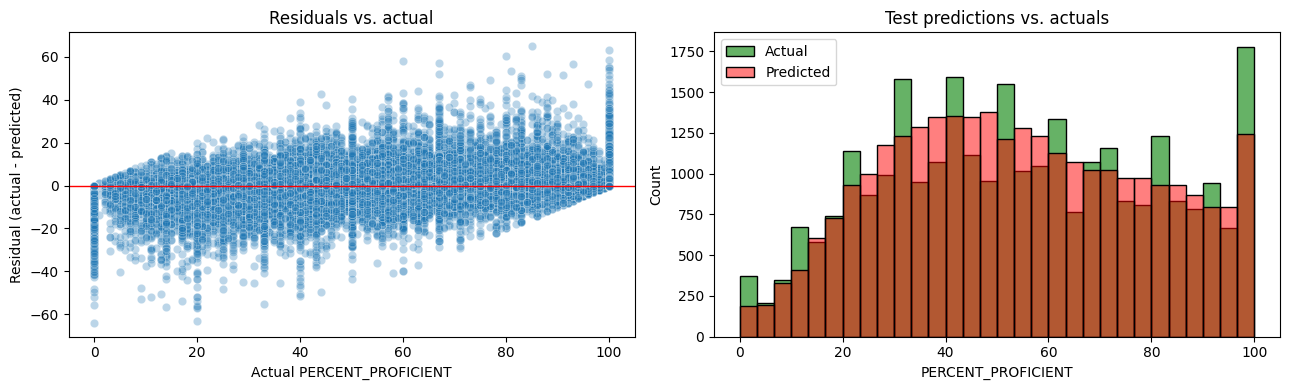

In [ ]:
resid = Y_test.values - test_preds

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Residuals vs actual
sns.scatterplot(x=Y_test.values, y=resid, alpha=0.3, ax=axes[0])
axes[0].axhline(0, color="red", linewidth=1)
axes[0].set_xlabel("Actual PERCENT_PROFICIENT")
axes[0].set_ylabel("Residual (actual - predicted)")
axes[0].set_title("Residuals vs. actual")

# Predicted vs actual distribution
sns.histplot(Y_test, bins=30, color="green", label="Actual", alpha=0.6, ax=axes[1])
sns.histplot(test_preds, bins=30, color="red", label="Predicted", alpha=0.5, ax=axes[1])
axes[1].legend()
axes[1].set_xlabel("PERCENT_PROFICIENT")
axes[1].set_title("Test predictions vs. actuals")

plt.tight_layout()
plt.show()

### Feature importance

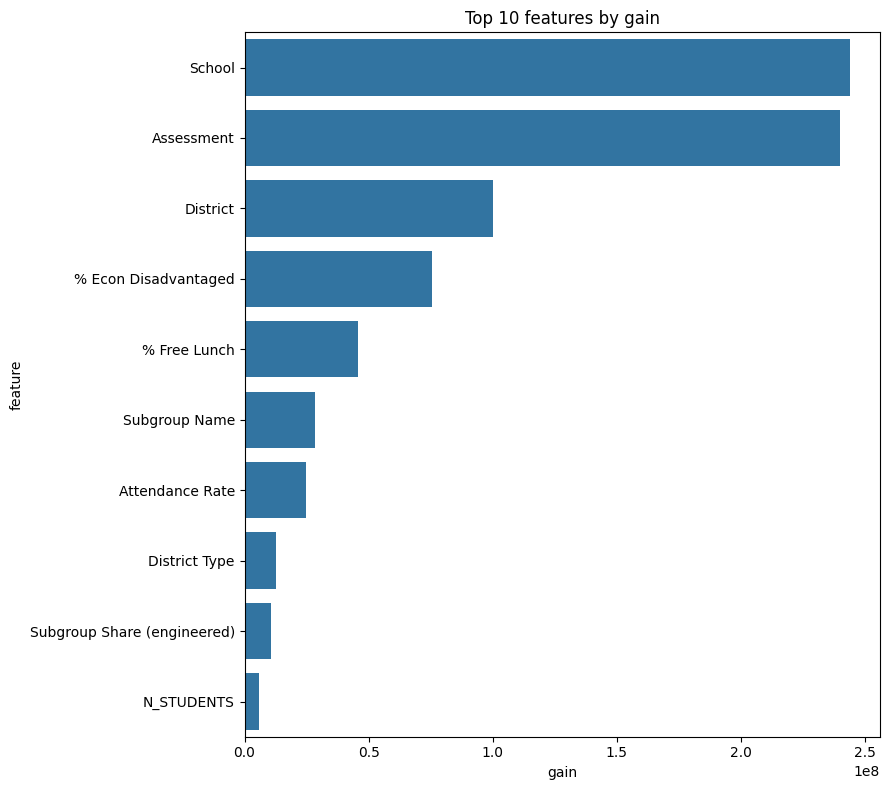

,feature,gain,split
54,School,2.438221e+08,46378
56,Assessment,2.397625e+08,49801
57,District,1.000838e+08,17136
38,% Econ Disadvantaged,7.548864e+07,461
5,% Free Lunch,4.581954e+07,374
55,Subgroup Name,2.849300e+07,16497
1,Attendance Rate,2.467893e+07,242
59,District Type,1.275471e+07,115
52,Subgroup Share (engineered),1.058074e+07,24835
0,N_STUDENTS,5.822726e+06,16017


In [ ]:
feat_imp = pd.DataFrame({
    "feature": full_lgbm_new_objective.booster_.feature_name(),
    "gain":    full_lgbm_new_objective.booster_.feature_importance(importance_type="gain"),
    "split":   full_lgbm_new_objective.booster_.feature_importance(importance_type="split"),
}).sort_values("gain", ascending=False)

feat_imp["feature"] = feat_imp["feature"].str.replace("cat__", "", regex=False).str.replace("scaled__", "", regex=False)

# Map raw column names to readable labels
LABEL_MAP = {
    # top-10 features
    "SCHOOL": "School",
    "ASSESSMENT_NAME": "Assessment",
    "DISTRICT": "District",
    "PERCENT_ECONOMICALLY_DISADVANTAGED": "% Econ Disadvantaged",
    "ATTENDANCE_RATE": "Attendance Rate",
    "PERCENT_FREE_LUNCH": "% Free Lunch",
    "SUBGROUP_NAME": "Subgroup Name",
    "DISTRICT_TYPE": "District Type",
    "GRADE_11": "Grade 11 Enrollment",
    "SUBGROUP_SHARE": "Subgroup Share (engineered)",
    "COUNTY": "County",
    # bottom-10 features
    "NUMBER_OF_COUNSELORS": "# Counselors",
    "PERCENT_IN_FOSTER_CARE": "% In Foster Care",
    "PRE_K": "Pre-K Enrollment",
    "PERCENT_AMERICAN_INDIAN": "% American Indian",
    "PERCENT_DROPOUT": "% Dropout",
    "NUMBER_OF_SOCIAL_WORKERS": "# Social Workers",
    "PERCENT_NON_DIPLOMA": "% Non-Diploma",
    "PERCENT_GED": "% GED",
    "PERCENT_PARENT_ARMED_FORCES": "% Parent in Armed Forces",
    "PERCENT_MIGRANT": "% Migrant",
}
feat_imp["feature"] = feat_imp["feature"].map(lambda f: LABEL_MAP.get(f, f))

plt.figure(figsize=(9, 8))
sns.barplot(data=feat_imp.head(10), x="gain", y="feature")
plt.title("Top 10 features by gain")
plt.tight_layout()
plt.show()
feat_imp.head(20).round(2)

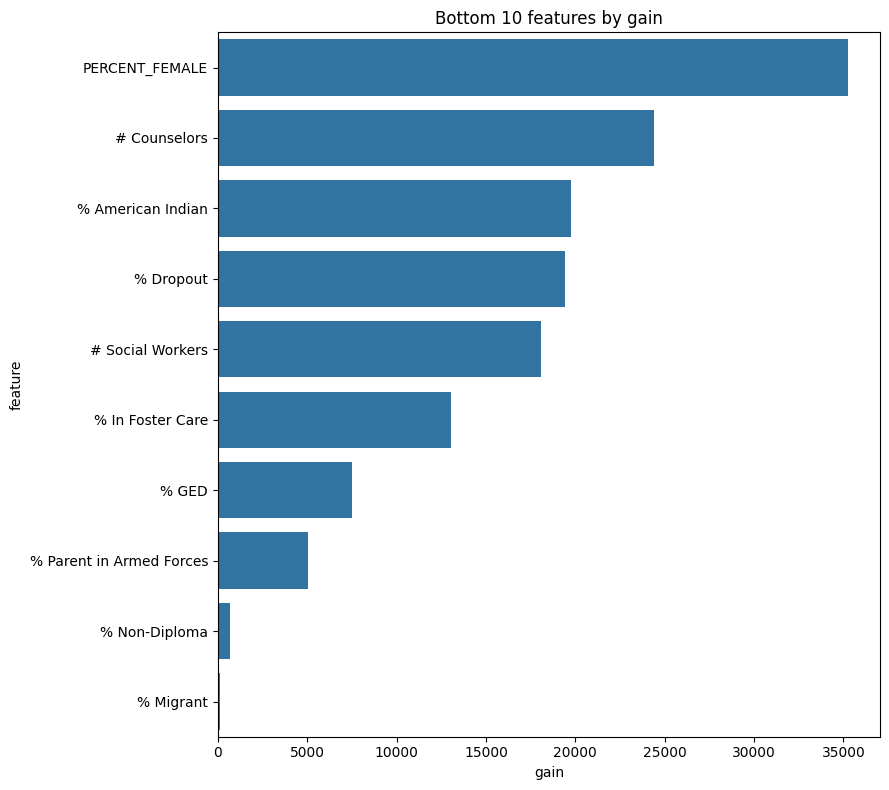

,feature,gain,split
49,FEDERAL_FUNDING_RATIO,98217.47,306
36,PERCENT_MULTIRACIAL,98153.84,137
19,GRADE_04,90501.39,182
15,K,71482.25,229
60,REGION,63836.48,168
17,GRADE_02,56101.81,130
16,GRADE_01,56047.51,150
45,PERCENT_STILL_ENROLLED,51435.73,57
14,Pre-K Enrollment,51253.15,160
43,PERCENT_DIPLOMA,41682.41,55


In [ ]:
 feat_imp["feature"] = feat_imp["feature"].map(lambda f: LABEL_MAP.get(f, f))

plt.figure(figsize=(9, 8))
sns.barplot(data=feat_imp.tail(10), x="gain", y="feature")
plt.title("Bottom 10 features by gain")
plt.tight_layout()
plt.show()

feat_imp.tail(20).round(2)

### Retrain on all labeled data for the final competition submission

In [ ]:
# Combine train and test back into a single full-data set
X_full = pd.concat([X_train, X_test], axis=0)
Y_full = pd.concat([Y_train, Y_test], axis=0)

# Reuse the tuned hyperparameters from the Optuna study
best_params_for_full = study.best_params.copy()
best_lambda_for_full = best_params_for_full.pop("LAMBDA")

# Fresh model with the SAME architecture as the held-out evaluation model
submission_model = lgb.LGBMRegressor(
    random_state=123,
    objective=make_relu_penalized_mse(best_lambda_for_full),
    n_jobs=-1,
    **best_params_for_full,
)

print(f"Fitting submission model on all {len(Y_full):,} labeled rows...")
submission_model.fit(
    X_full, Y_full,
    categorical_feature=CATEGORICAL_COLS_PROCESSED,
)

# Persist this model so we don't have to retrain if the kernel restarts
submission_model.booster_.save_model("submission_model_full_data.txt")
print("Submission model saved to submission_model_full_data.txt")
print(f"Trained on {len(Y_full):,} rows  (vs. {len(Y_train):,} for the held-out eval model)")

Fitting submission model on all 144,921 labeled rows...
[LightGBM] [Warning] Categorical features with more bins than the configured maximum bin number found.
[LightGBM] [Warning] For categorical features, max_bin and max_bin_by_feature may be ignored with a large number of categories.
[LightGBM] [Info] Using self-defined objective function
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.036939 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 12980
[LightGBM] [Info] Number of data points in the train set: 144921, number of used features: 61
[LightGBM] [Warning] Provided parameters constrain tree depth (max_depth=12) without explicitly setting 'num_leaves'. This can lead to underfitting. To resolve this warning, pass 'num_leaves' (<=4096) in params. Alternatively, pass (max_depth=-1) and just use 'num_leaves' to constrain model complexity.
[LightGBM] [Info] Using self-defined objective function
[Light

## 11. Build the submission

In [ ]:
# 1. Joins
submission_data = (
    test_df
    .merge(schools, on="SCHOOL", how="left")
    .merge(district, on="DISTRICT", how="left")
)
assert len(submission_data) == len(test_df)

# 2. Drop same high-missing columns
submission_data = submission_data.drop(columns=HIGH_MISSING_COLS)

# 3. Impute using training-set statistics (df_clean)
sub_na_columns = [c for c in submission_data.columns if submission_data[c].isna().any()]
submission_data = grouped_median_imputer(
    submission_data,
    group_col="SCHOOL",
    na_columns=sub_na_columns,
    source_df=df_clean,  # training data
)

In [ ]:
# 4. Feature engineering (same function, applied to submission rows)
submission_data = add_features(submission_data)

# 5. Same preprocessor (transform only - never refit on test data)
sub_x = preprocessor.transform(submission_data)

In [ ]:
# 6. Predict and clip
y_pred = submission_model.predict(sub_x)
y_pred = np.clip(y_pred, 0, 100)

submission_data["PERCENT_PROFICIENT"] = y_pred

# Build the two-column submission file
submission = submission_data[["ASSESSMENT_ID", "PERCENT_PROFICIENT"]]
submission.to_csv("full_lgbm_kaggle_submission.csv", index=False)

print(f"Wrote {len(submission):,} rows to full_lgbm_kaggle_submission.csv")
print(f"Prediction range: [{y_pred.min():.2f}, {y_pred.max():.2f}]")
submission.head()

Wrote 48,307 rows to full_lgbm_kaggle_submission.csv
Prediction range: [0.00, 100.00]


,ASSESSMENT_ID,PERCENT_PROFICIENT
0,8af5e0382a81,67.041297
1,e1591bf8db41,47.481315
2,547ec44dcea6,35.870877
3,0e200399fc40,59.817216
4,c2c40438dac7,83.726528


### Compare submission distribution to training target

A sanity check: predicted proficiency rates should roughly match the shape
of the training target distribution, including the spikes near 0 and 100.

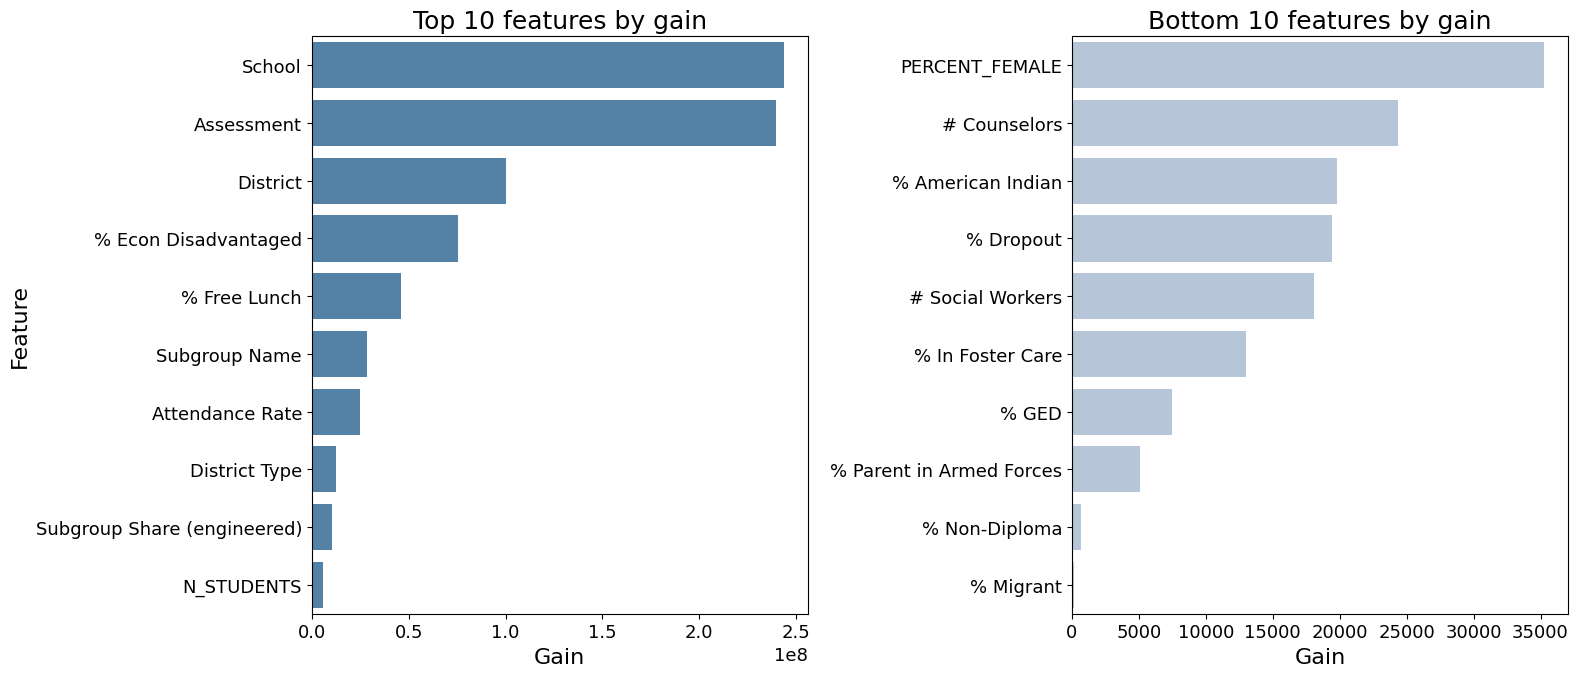

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams.update({
    "font.size": 14,
    "axes.titlesize": 18,
    "axes.labelsize": 16,
    "xtick.labelsize": 13,
    "ytick.labelsize": 13,
})

feat_imp["feature"] = feat_imp["feature"].str.replace("cat__", "", regex=False).str.replace("scaled__", "", regex=False)

LABEL_MAP = {
    # top-10 features
    "SCHOOL": "School",
    "ASSESSMENT_NAME": "Assessment",
    "DISTRICT": "District",
    "PERCENT_ECONOMICALLY_DISADVANTAGED": "% Econ Disadvantaged",
    "ATTENDANCE_RATE": "Attendance Rate",
    "PERCENT_FREE_LUNCH": "% Free Lunch",
    "SUBGROUP_NAME": "Subgroup Name",
    "DISTRICT_TYPE": "District Type",
    "GRADE_11": "Grade 11 Enrollment",
    "SUBGROUP_SHARE": "Subgroup Share (engineered)",
    # bottom-10 features
    "NUMBER_OF_COUNSELORS": "# Counselors",
    "PERCENT_IN_FOSTER_CARE": "% In Foster Care",
    "PRE_K": "Pre-K Enrollment",
    "PERCENT_AMERICAN_INDIAN": "% American Indian",
    "PERCENT_DROPOUT": "% Dropout",
    "NUMBER_OF_SOCIAL_WORKERS": "# Social Workers",
    "PERCENT_NON_DIPLOMA": "% Non-Diploma",
    "PERCENT_GED": "% GED",
    "PERCENT_PARENT_ARMED_FORCES": "% Parent in Armed Forces",
    "PERCENT_MIGRANT": "% Migrant",
}
feat_imp["feature"] = feat_imp["feature"].map(lambda f: LABEL_MAP.get(f, f))

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

sns.barplot(data=feat_imp.head(10), x="gain", y="feature", ax=axes[0], color="steelblue")
axes[0].set_title("Top 10 features by gain", fontsize=18)
axes[0].set_xlabel("Gain", fontsize=16)
axes[0].set_ylabel("Feature", fontsize=16)
axes[0].tick_params(axis="both", labelsize=13)

sns.barplot(data=feat_imp.tail(10), x="gain", y="feature", ax=axes[1], color="lightsteelblue")
axes[1].set_title("Bottom 10 features by gain", fontsize=18)
axes[1].set_xlabel("Gain", fontsize=16)
axes[1].set_ylabel("")
axes[1].tick_params(axis="both", labelsize=13)

plt.tight_layout()
plt.savefig("feature_importance_combined.png", dpi=150, bbox_inches="tight")
plt.show()

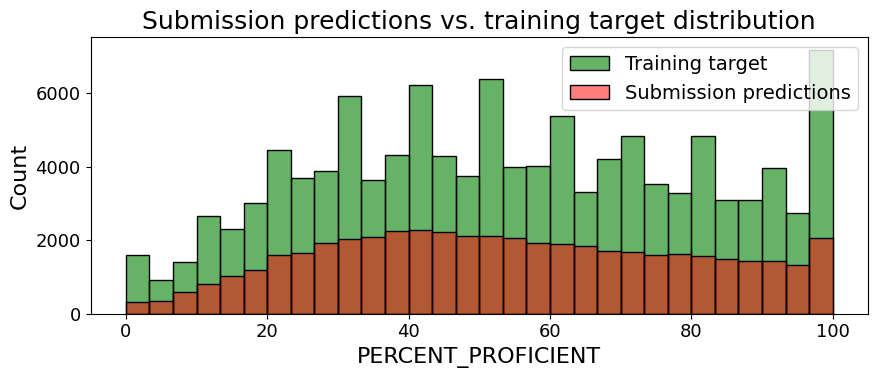

In [ ]:
plt.figure(figsize=(9, 4))
sns.histplot(Y_train, bins=30, color="green", alpha=0.6, label="Training target")
sns.histplot(submission["PERCENT_PROFICIENT"], bins=30, color="red", alpha=0.5,
             label="Submission predictions")
plt.xlabel("PERCENT_PROFICIENT")
plt.legend()
plt.title("Submission predictions vs. training target distribution")
plt.tight_layout()
plt.show()